# UTS Milestone 1 — Prediksi Status Berlangganan (Subscription Status) pada Customer Shopping Trends

**Dataset:** https://www.kaggle.com/datasets/iamsouravbanerjee/customer-shopping-trends-dataset

**Cara menjalankan**
1. Unduh CSV dari Kaggle, letakkan di folder `data/` (mis. `data/shopping_trends.csv`), *atau* jalankan `pip install kagglehub` lalu biarkan sel loading mengunduh otomatis.
2. `pip install pandas numpy scikit-learn matplotlib seaborn`
3. Jalankan semua sel dari atas ke bawah (Run All). Semua angka di laporan harus diambil dari output notebook ini (tabel disimpan di folder `results/`, gambar di `figures/`).

> Teks bertanda **[ISI]** adalah interpretasi yang harus kalian tulis sendiri setelah melihat output.

In [7]:
   import os, shutil
   from google.colab import files
   os.makedirs("data", exist_ok=True)
   up = files.upload()
   for name in up:
       shutil.move(name, f"data/{name}")
   print(os.listdir("data"))

Saving shopping_trends_updated.csv to shopping_trends_updated.csv
['shopping_trends_updated.csv']


## A. Problem formulation
- **Masalah:** Memprediksi apakah pelanggan berlangganan (`Subscription Status` = Yes) berdasarkan profil dan perilaku belanjanya.
- **Mengapa penting:** **[ISI]** (mis. menargetkan promosi program langganan secara efisien).
- **Jenis pendekatan:** klasifikasi biner, *supervised*, classical ML.
- **Target:** `Subscription Status` (Yes=1, No=0). Kelas tidak seimbang sehingga akurasi saja tidak memadai.
- **Batasan:** hanya fitur yang tersedia saat prediksi; tanpa deep learning; dataset tidak diganti karena hasil awal jelek.
- **Catatan jujur:** dataset ini kemungkinan sintetis, sehingga sinyal prediktif bisa lemah. Hasil mendekati baseline tetap temuan sah dan harus dilaporkan apa adanya.

In [8]:
import glob, os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
SEED = 42
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)

files = glob.glob("data/*.csv")
if not files:
    import kagglehub
    p = kagglehub.dataset_download("iamsouravbanerjee/customer-shopping-trends-dataset")
    files = glob.glob(os.path.join(p, "*.csv"))
print("File:", files)
df = pd.read_csv(files[0])
df.shape

File: ['data/shopping_trends_updated.csv']


(3900, 18)

## B. Dataset dan data understanding

In [9]:
print("Observasi:", df.shape[0], "| Kolom:", df.shape[1])
display(df.head())
display(pd.DataFrame({"dtype": df.dtypes, "n_missing": df.isna().sum(), "n_unique": df.nunique()}))

Observasi: 3900 | Kolom: 18


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


,dtype,n_missing,n_unique
Customer ID,int64,0,3900
Age,int64,0,53
Gender,object,0,2
Item Purchased,object,0,25
Category,object,0,4
Purchase Amount (USD),int64,0,81
Location,object,0,50
Size,object,0,4
Color,object,0,25
Season,object,0,4


In [10]:
print("Duplikat baris:", df.duplicated().sum())
print("Customer ID unik:", df["Customer ID"].is_unique, "(unit observasi = 1 baris per pelanggan jika True)")
display(df.describe().T)
display(df.describe(include="object").T)

Duplikat baris: 0
Customer ID unik: True (unit observasi = 1 baris per pelanggan jika True)


,count,mean,std,min,25%,50%,75%,max
Customer ID,3900.0,1950.500000,1125.977353,1.0,975.75,1950.5,2925.25,3900.0
Age,3900.0,44.068462,15.207589,18.0,31.00,44.0,57.00,70.0
Purchase Amount (USD),3900.0,59.764359,23.685392,20.0,39.00,60.0,81.00,100.0
Review Rating,3900.0,3.749949,0.716223,2.5,3.10,3.7,4.40,5.0
Previous Purchases,3900.0,25.351538,14.447125,1.0,13.00,25.0,38.00,50.0


,count,unique,top,freq
Gender,3900,2,Male,2652
Item Purchased,3900,25,Blouse,171
Category,3900,4,Clothing,1737
Location,3900,50,Montana,96
Size,3900,4,M,1755
Color,3900,25,Olive,177
Season,3900,4,Spring,999
Subscription Status,3900,2,No,2847
Shipping Type,3900,6,Free Shipping,675
Discount Applied,3900,2,No,2223


**Ringkasan kualitas data:** **[ISI]** (missing, duplikat, outlier, nilai tak wajar, dll. sesuai output di atas).

In [12]:
TARGET = "Subscription Status"
df["y"] = (df[TARGET] == "Yes").astype(int)
print(df["y"].value_counts(), "\n", df["y"].value_counts(normalize=True).round(3))
# Cek redundansi fitur
print("\nDiscount Applied == Promo Code Used pada semua baris?",
      (df["Discount Applied"] == df["Promo Code Used"]).all())
# Kolom 'Preferred Payment Method' tidak tersedia di dataset ini, jadi baris pengecekan tersebut dihapus.

y
0    2847
1    1053
Name: count, dtype: int64 
 y
0    0.73
1    0.27
Name: proportion, dtype: float64

Discount Applied == Promo Code Used pada semua baris? True


## C. EDA dan temuan awal

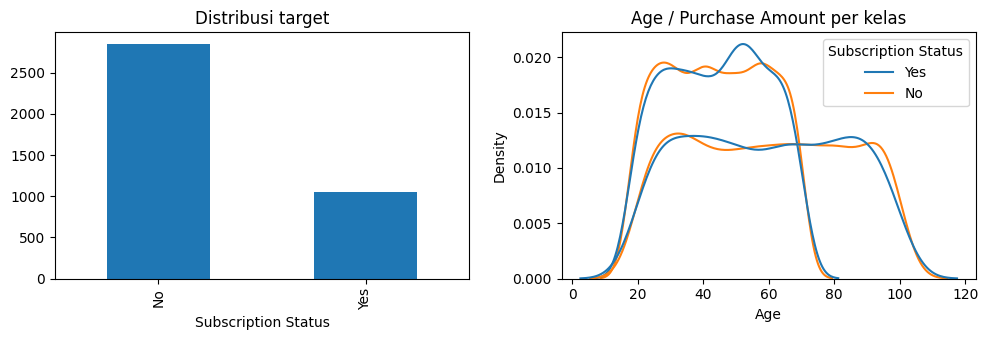

In [13]:
cat_cols_eda = ["Gender","Category","Season","Shipping Type","Discount Applied",
                "Payment Method","Frequency of Purchases"]
num_cols_eda = ["Age","Purchase Amount (USD)","Review Rating","Previous Purchases"]

fig, ax = plt.subplots(1,2, figsize=(10,3.5))
df[TARGET].value_counts().plot.bar(ax=ax[0], title="Distribusi target")
for c in num_cols_eda[:2]:
    sns.kdeplot(data=df, x=c, hue=TARGET, common_norm=False, ax=ax[1] if c==num_cols_eda[0] else ax[1])
ax[1].set_title("Age / Purchase Amount per kelas")
plt.tight_layout(); plt.savefig("figures/eda_target.png", dpi=150); plt.show()

,fitur,nilai,rate_subscribe,n,selisih_vs_base
1,Discount Applied,Yes,0.627907,1677,0.357907
0,Discount Applied,No,0.000000,2223,-0.270000
0,Gender,Female,0.000000,1248,-0.270000
1,Gender,Male,0.397059,2652,0.127059
3,Payment Method,Debit Card,0.298742,636,0.028742
0,Shipping Type,2-Day Shipping,0.244019,627,-0.025981
1,Shipping Type,Express,0.294118,646,0.024118
5,Shipping Type,Store Pickup,0.292308,650,0.022308
5,Frequency of Purchases,Quarterly,0.248668,563,-0.021332
6,Frequency of Purchases,Weekly,0.291280,539,0.021280


Age               Purchase Amount (USD)                \
                      mean median    std                  mean median    std   
Subscription Status                                                            
No                   44.01   44.0  15.27                 59.87   60.0  23.78   
Yes                  44.23   45.0  15.04                 59.49   60.0  23.45   

                    Review Rating              Previous Purchases         \
                             mean median   std               mean median   
Subscription Status                                                        
No                           3.75    3.8  0.72              25.08   25.0   
Yes                          3.74    3.7  0.72              26.08   26.0   

                            
                       std  
Subscription Status         
No                   14.55  
Yes                  14.14

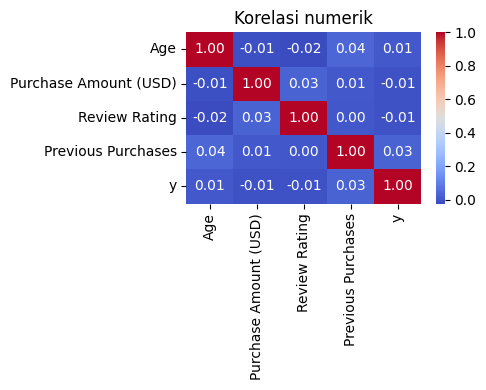

In [14]:
# Tingkat langganan per kategori (selisih kecil dari base rate = sinyal lemah)
base = df["y"].mean()
rows = []
for c in cat_cols_eda:
    g = df.groupby(c)["y"].agg(["mean","count"]).reset_index()
    g.insert(0,"fitur",c); g.columns=["fitur","nilai","rate_subscribe","n"]
    rows.append(g)
rate_tbl = pd.concat(rows); rate_tbl["selisih_vs_base"] = rate_tbl["rate_subscribe"]-base
rate_tbl.to_csv("results/eda_rate_per_kategori.csv", index=False)
display(rate_tbl.sort_values("selisih_vs_base", key=abs, ascending=False).head(10))

num_summary = df.groupby(TARGET)[num_cols_eda].agg(["mean","median","std"]).round(2)
display(num_summary)
plt.figure(figsize=(5,4)); sns.heatmap(df[num_cols_eda+["y"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Korelasi numerik"); plt.tight_layout(); plt.savefig("figures/eda_corr.png", dpi=150); plt.show()

**Temuan awal EDA:** **[ISI]** Tulis 3–5 temuan yang benar-benar terlihat dari tabel/grafik di atas (angka spesifik), termasuk apakah ada fitur yang jelas membedakan pelanggan berlangganan atau tidak.

## D. Preprocessing & anti-leakage
Keputusan (sesuaikan dengan hasil EDA):
- `Customer ID`: dibuang (identifier, bukan fitur).
- `Promo Code Used`: dibuang bila terbukti identik dengan `Discount Applied` (redundan).
- **Split train/test dilakukan SEBELUM fitting apapun**; imputasi, scaling, dan one-hot dipelajari hanya dari data latih lewat `Pipeline`/`ColumnTransformer`, termasuk di dalam cross-validation.
- `Frequency of Purchases` dipetakan ke ordinal (perkiraan transaksi per tahun) sebagai bagian dari feature engineering.

In [15]:
from sklearn.model_selection import train_test_split
DROP = ["Customer ID", "Promo Code Used", TARGET, "y"]
X = df.drop(columns=DROP); y = df["y"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(X_train.shape, X_test.shape, y_train.mean().round(3), y_test.mean().round(3))

(3120, 15) (780, 15) 0.27 0.271


## E. Initial feature engineering
| Fitur baru | Alasan | Dampak yang diharapkan |
|---|---|---|
| `Age_Group` | pola usia bisa non-linear | membantu model linear |
| `Freq_per_Year` | `Frequency of Purchases` bersifat ordinal | menangkap urutan frekuensi |
| `Amount_per_Prev` | rasio nilai belanja terhadap riwayat | proxy intensitas belanja |

In [16]:
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

FREQ_MAP = {"Weekly":52,"Bi-Weekly":26,"Fortnightly":26,"Monthly":12,
            "Quarterly":4,"Every 3 Months":4,"Annually":1}

def add_features(d):
    d = d.copy()
    d["Age_Group"] = pd.cut(d["Age"], [0,25,35,45,55,120],
                            labels=["<=25","26-35","36-45","46-55","56+"]).astype(str)
    d["Freq_per_Year"] = d["Frequency of Purchases"].map(FREQ_MAP)
    d["Amount_per_Prev"] = d["Purchase Amount (USD)"] / (d["Previous Purchases"] + 1)
    return d

fe = FunctionTransformer(add_features)
sample = add_features(X_train)
num_cols = ["Age","Purchase Amount (USD)","Review Rating","Previous Purchases","Freq_per_Year","Amount_per_Prev"]
cat_cols = [c for c in sample.columns if c not in num_cols]
print("Numerik:", num_cols); print("Kategorikal:", cat_cols)

from sklearn.impute import SimpleImputer
def make_pre():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
    ])

Numerik: ['Age', 'Purchase Amount (USD)', 'Review Rating', 'Previous Purchases', 'Freq_per_Year', 'Amount_per_Prev']
Kategorikal: ['Gender', 'Item Purchased', 'Category', 'Location', 'Size', 'Color', 'Season', 'Shipping Type', 'Discount Applied', 'Payment Method', 'Frequency of Purchases', 'Age_Group']


## F. Baseline dan model kandidat
- **Baseline 1:** `DummyClassifier(most_frequent)` — menunjukkan jebakan akurasi pada kelas tidak seimbang.
- **Baseline 2:** `DummyClassifier(stratified)` — tebakan acak sesuai proporsi kelas.
- **Kandidat:** Logistic Regression (interpretable), Decision Tree (terbatas depth), Random Forest, HistGradientBoosting.

In [17]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

models = {
 "Baseline: Dummy most_frequent": DummyClassifier(strategy="most_frequent"),
 "Baseline: Dummy stratified":    DummyClassifier(strategy="stratified", random_state=SEED),
 "LogReg (balanced)":   LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
 "DecisionTree (d=4)":  DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=SEED),
 "RandomForest":        RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                              n_jobs=-1, random_state=SEED),
 "HistGradientBoosting":HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200,
                                              class_weight="balanced", random_state=SEED),
}
def make_pipe(m): return Pipeline([("fe", fe), ("pre", make_pre()), ("clf", m)])

## G. Evaluation design
- **Hold-out:** 80/20 stratified, test set dikunci dan hanya dipakai sekali untuk pelaporan.
- **Validasi:** Repeated Stratified 5-fold × 2 pada data latih (stratified karena kelas tidak seimbang; fitting preprocessing di dalam fold).
- **Metrik:** PR-AUC (Average Precision) sebagai metrik utama untuk kelas minoritas; ROC-AUC, F1 (kelas Yes), balanced accuracy, dan accuracy (hanya pembanding).
- **Threshold** default 0,5 untuk metrik berbasis label; tuning threshold ditunda ke UAS.

In [18]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
scoring = {"pr_auc":"average_precision","roc_auc":"roc_auc","f1":"f1",
           "bal_acc":"balanced_accuracy","acc":"accuracy"}
cv_rows = []
for name, m in models.items():
    r = cross_validate(make_pipe(m), X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    row = {"model": name}
    for k in scoring: row[k] = f"{r['test_'+k].mean():.3f} ± {r['test_'+k].std():.3f}"
    cv_rows.append(row)
cv_tbl = pd.DataFrame(cv_rows); cv_tbl.to_csv("results/cv_results.csv", index=False)
display(cv_tbl)

,model,pr_auc,roc_auc,f1,bal_acc,acc
0,Baseline: Dummy most_frequent,0.270 ± 0.001,0.500 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.730 ± 0.001
1,Baseline: Dummy stratified,0.277 ± 0.009,0.514 ± 0.022,0.293 ± 0.032,0.514 ± 0.022,0.614 ± 0.017
2,LogReg (balanced),0.618 ± 0.043,0.885 ± 0.017,0.761 ± 0.018,0.880 ± 0.012,0.833 ± 0.015
3,DecisionTree (d=4),0.618 ± 0.027,0.882 ± 0.014,0.757 ± 0.019,0.877 ± 0.014,0.831 ± 0.016
4,RandomForest,0.654 ± 0.044,0.897 ± 0.014,0.765 ± 0.016,0.886 ± 0.010,0.834 ± 0.015
5,HistGradientBoosting,0.644 ± 0.044,0.892 ± 0.016,0.761 ± 0.017,0.881 ± 0.012,0.832 ± 0.016


## H. Initial results — evaluasi hold-out

In [19]:
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score,
                             balanced_accuracy_score, accuracy_score, confusion_matrix)
ho_rows, fitted = [], {}
for name, m in models.items():
    p = make_pipe(m).fit(X_train, y_train); fitted[name] = p
    pred = p.predict(X_test)
    proba = p.predict_proba(X_test)[:,1]
    ho_rows.append({"model":name, "pr_auc":average_precision_score(y_test,proba),
        "roc_auc":roc_auc_score(y_test,proba), "f1":f1_score(y_test,pred),
        "bal_acc":balanced_accuracy_score(y_test,pred), "acc":accuracy_score(y_test,pred)})
ho_tbl = pd.DataFrame(ho_rows).round(3); ho_tbl.to_csv("results/holdout_results.csv", index=False)
display(ho_tbl)
print("Rasio kelas positif (PR-AUC acak ≈ ini):", round(y_test.mean(),3))

,model,pr_auc,roc_auc,f1,bal_acc,acc
0,Baseline: Dummy most_frequent,0.271,0.500,0.000,0.500,0.729
1,Baseline: Dummy stratified,0.280,0.522,0.303,0.522,0.622
2,LogReg (balanced),0.681,0.910,0.801,0.908,0.865
3,DecisionTree (d=4),0.673,0.909,0.795,0.902,0.862
4,RandomForest,0.674,0.906,0.799,0.907,0.864
5,HistGradientBoosting,0.688,0.910,0.799,0.907,0.864


Rasio kelas positif (PR-AUC acak ≈ ini): 0.271


Model kandidat terbaik (PR-AUC hold-out): HistGradientBoosting


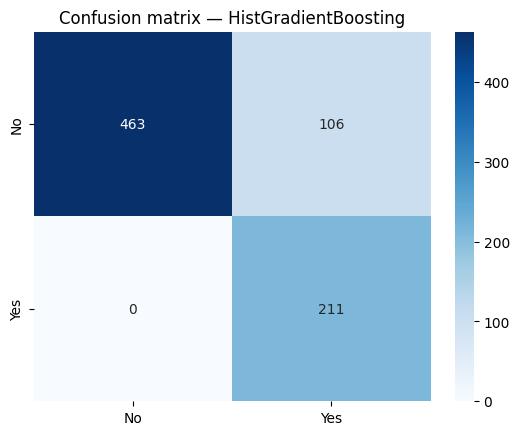

In [20]:
best = ho_tbl.iloc[2:].sort_values("pr_auc", ascending=False).iloc[0]["model"]
print("Model kandidat terbaik (PR-AUC hold-out):", best)
cm = confusion_matrix(y_test, fitted[best].predict(X_test))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No","Yes"], yticklabels=["No","Yes"])
plt.title(f"Confusion matrix — {best}"); plt.savefig("figures/cm_best.png", dpi=150); plt.show()

In [21]:
   !zip -r hasil_uts.zip results figures
   from google.colab import files
   files.download("hasil_uts.zip")

  adding: results/ (stored 0%)
  adding: results/cv_results.csv (deflated 54%)
  adding: results/holdout_results.csv (deflated 37%)
  adding: results/eda_rate_per_kategori.csv (deflated 55%)
  adding: figures/ (stored 0%)
  adding: figures/eda_target.png (deflated 8%)
  adding: figures/cm_best.png (deflated 22%)
  adding: figures/eda_corr.png (deflated 9%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Analisis awal:** **[ISI]** Bandingkan model vs baseline dengan angka dari tabel CV *dan* hold-out. Apakah selisihnya bermakna relatif terhadap std antar-fold? Apakah hasil CV dan hold-out konsisten? Jika kandidat nyaris sama dengan baseline, jelaskan kemungkinan penyebab (mis. sinyal lemah/data sintetis) dan jangan mengklaim performa yang tidak ada.

**Keterbatasan:** **[ISI]** (mis. satu dataset sintetis, tidak ada tuning, threshold default, tidak ada waktu/urutan transaksi).

## I. Rencana pasca-UTS (sesuaikan dengan temuan)
| Minggu | Pekerjaan | Dasar dari temuan UTS |
|---|---|---|
| 1 | Feature selection / uji fitur tambahan | **[ISI]** |
| 2 | Hyperparameter tuning (RandomizedSearchCV, nested CV) | **[ISI]** |
| 3 | Tuning threshold + penanganan imbalance (class_weight vs resampling di dalam fold) | **[ISI]** |
| 4 | Error analysis, interpretasi (permutation importance / SHAP) | **[ISI]** |
| 5 | Pemilihan model final, laporan UAS, presentasi | — |

**Catatan eksperimen:** seed=42; versi library: jalankan `pip freeze > requirements.txt`.